# Remember : 

Threshold Tuning is not perfromed on Test Set.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [24]:
sns.set_theme(style="whitegrid")

In [25]:
# Generate an imbalanced binary classification dataset
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=0.8,
    flip_y=0.01,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Target"].value_counts().sort_index())
print("\nClass percentages:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (2000, 3)

Class distribution:
Target
0    1893
1     107
Name: count, dtype: int64

Class percentages:
Target
0    94.65
1     5.35
Name: proportion, dtype: float64


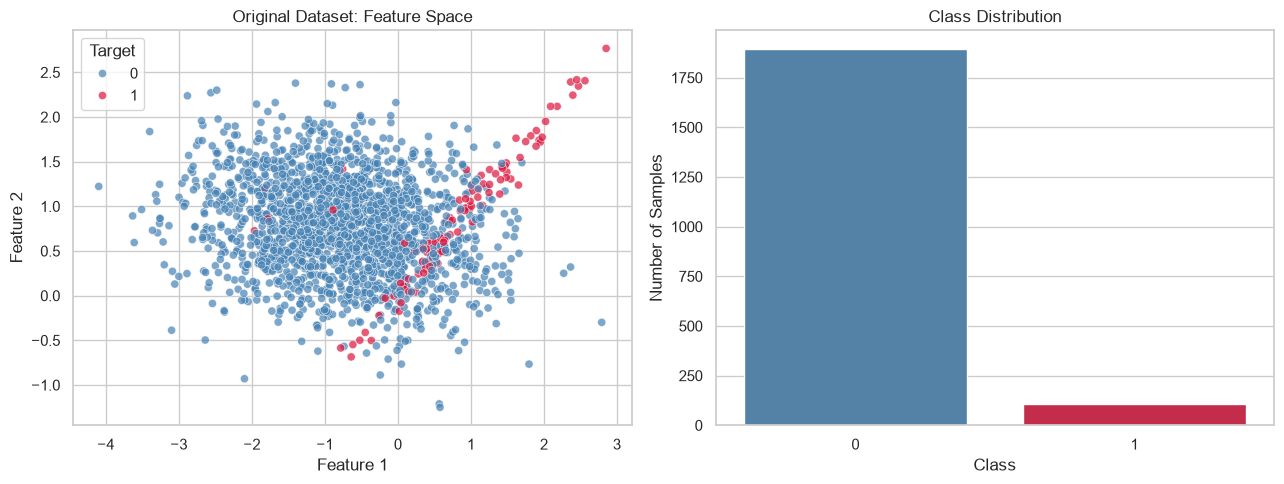

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Original Dataset: Feature Space")

# Class counts
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training distribution:
0    1420
1      80
Name: count, dtype: int64

Test distribution:
0    473
1     27
Name: count, dtype: int64


## Splitting again to form a validation set which will be used for threshold tuning

In [28]:
# Split the original training data again.
# The original test set remains untouched.
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

print("Sub-training samples:", len(X_subtrain))
print("Validation samples:", len(X_val))

print("\nSub-training class distribution:")
print(pd.Series(y_subtrain).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())


Sub-training samples: 1125
Validation samples: 375

Sub-training class distribution:
0    1065
1      60
Name: count, dtype: int64

Validation class distribution:
0    355
1     20
Name: count, dtype: int64


In [29]:
# Learn the scaling values from training data only.
threshold_scaler = StandardScaler()

X_subtrain_scaled = threshold_scaler.fit_transform(X_subtrain)
X_val_scaled = threshold_scaler.transform(X_val)

# Train Logistic Regression.
threshold_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

threshold_model.fit(X_subtrain_scaled, y_subtrain)

# Predict probabilities for the validation examples.
val_proba = threshold_model.predict_proba(X_val_scaled)[:, 1]

print("First 10 actual labels:")
print(y_val[:10])

print("\nFirst 10 predicted fraud probabilities:")
print(val_proba[:10].round(3))


First 10 actual labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted fraud probabilities:
[0.011 0.003 0.163 0.007 0.012 0.021 0.007 0.005 0.007 0.053]


In [30]:
threshold_values = np.arange(0.10, 0.91, 0.10)

results = []

for threshold in threshold_values:

    # Convert probabilities into class labels.
    val_pred = (val_proba >= threshold).astype(int)

    # Measure minority-class performance.
    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))


,Threshold,Precision,Recall,F1
0,0.1,0.341,0.75,0.469
1,0.2,0.400,0.60,0.480
2,0.3,0.529,0.45,0.486
3,0.4,0.538,0.35,0.424
4,0.5,0.571,0.20,0.296
5,0.6,0.667,0.10,0.174
6,0.7,0.500,0.05,0.091
7,0.8,0.000,0.00,0.000
8,0.9,0.000,0.00,0.000


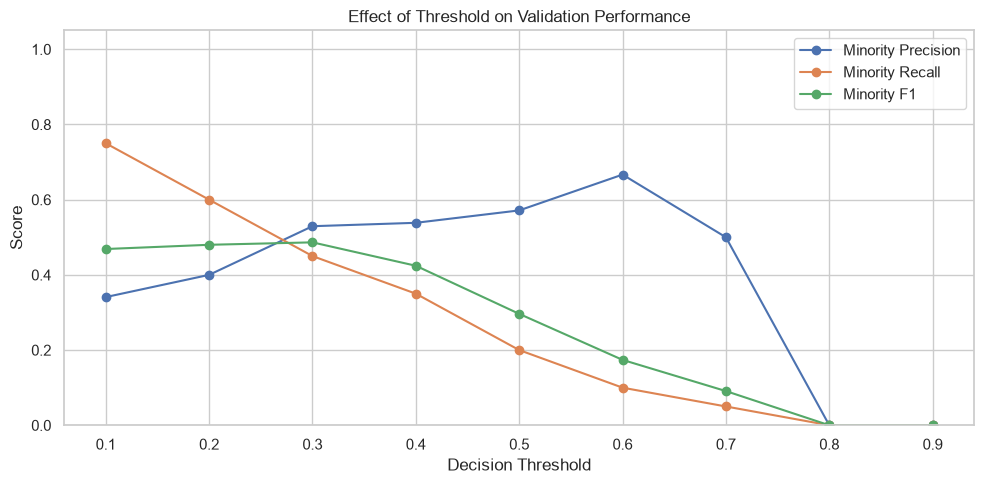

In [31]:

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Minority Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Minority Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="Minority F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Effect of Threshold on Validation Performance")

plt.xticks(threshold_values.round(2))
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## Choosing Threshold where the F1 Score is maximum. (Just as an example)

## Based on the business metric and importance we can choose the threshold accordingly.

In [32]:
best_idx = threshold_results["F1"].idxmax()

best_threshold = threshold_results.loc[
    best_idx, "Threshold"
]

print("Selected threshold:", round(best_threshold, 2))
print("Validation precision:",
      round(threshold_results.loc[best_idx, "Precision"], 3))
print("Validation recall:",
      round(threshold_results.loc[best_idx, "Recall"], 3))
print("Validation F1:",
      round(threshold_results.loc[best_idx, "F1"], 3))

Selected threshold: 0.3
Validation precision: 0.529
Validation recall: 0.45
Validation F1: 0.486


DEFAULT THRESHOLD: 0.50
              precision    recall  f1-score   support

           0      0.957     0.992     0.974       355
           1      0.571     0.200     0.296        20

    accuracy                          0.949       375
   macro avg      0.764     0.596     0.635       375
weighted avg      0.936     0.949     0.938       375


SELECTED THRESHOLD: 0.3
              precision    recall  f1-score   support

           0      0.969     0.977     0.973       355
           1      0.529     0.450     0.486        20

    accuracy                          0.949       375
   macro avg      0.749     0.714     0.730       375
weighted avg      0.946     0.949     0.947       375



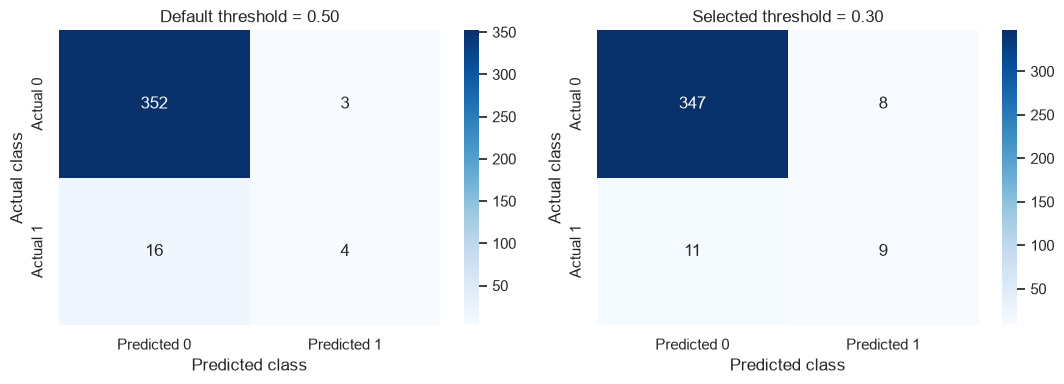

In [33]:

default_pred = (val_proba >= 0.50).astype(int)
tuned_pred = (val_proba >= best_threshold).astype(int)

print("DEFAULT THRESHOLD: 0.50")
print(classification_report(y_val, default_pred, digits=3))

print("\nSELECTED THRESHOLD:", round(best_threshold, 2))
print(classification_report(y_val, tuned_pred, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, predictions, title in [
    (axes[0], default_pred, "Default threshold = 0.50"),
    (axes[1], tuned_pred, f"Selected threshold = {best_threshold:.2f}")
]:
    sns.heatmap(
        confusion_matrix(y_val, predictions),
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()


## Evaluating on the final test set

In [34]:

# Use the same scaler and model fitted earlier.
X_test_threshold_scaled = threshold_scaler.transform(X_test)

test_proba = threshold_model.predict_proba(
    X_test_threshold_scaled
)[:, 1]

test_default_pred = (test_proba >= 0.50).astype(int)
test_tuned_pred = (test_proba >= best_threshold).astype(int)

print("TEST RESULTS — DEFAULT THRESHOLD")
print(classification_report(y_test, test_default_pred, digits=3))

print("\nTEST RESULTS — SELECTED THRESHOLD")
print(classification_report(y_test, test_tuned_pred, digits=3))


TEST RESULTS — DEFAULT THRESHOLD
              precision    recall  f1-score   support

           0      0.949     0.992     0.970       473
           1      0.333     0.074     0.121        27

    accuracy                          0.942       500
   macro avg      0.641     0.533     0.546       500
weighted avg      0.916     0.942     0.924       500


TEST RESULTS — SELECTED THRESHOLD
              precision    recall  f1-score   support

           0      0.954     0.966     0.960       473
           1      0.238     0.185     0.208        27

    accuracy                          0.924       500
   macro avg      0.596     0.576     0.584       500
weighted avg      0.915     0.924     0.919       500



## Prodcution Grade Threshold Tuning Technique

## Acheived Using __TunedThresholdClassifierCV__

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Model + preprocessing
base_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Stratified 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


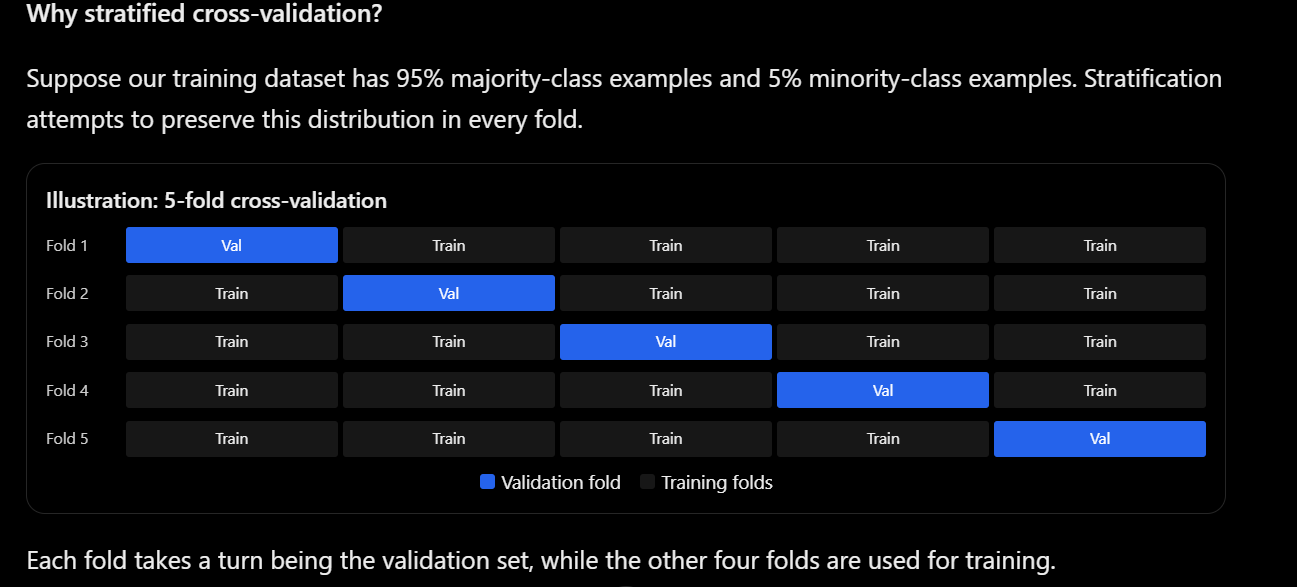

In [36]:
tuned_model = TunedThresholdClassifierCV(
    estimator=base_model,
    scoring="f1",
    cv=cv,
    thresholds=100,
    refit=True,
    store_cv_results=True
)

tuned_model.fit(X_train, y_train)

print("Best threshold:", tuned_model.best_threshold_)
print("Best CV F1-score:", tuned_model.best_score_)

Best threshold: 0.30892627753642027
Best CV F1-score: 0.4448195443543357


## Visualizing CV Results

,thresholds,scores
0,0.000041,0.101266
1,0.009401,0.166399
2,0.018761,0.210160
3,0.028122,0.248829
4,0.037482,0.286335


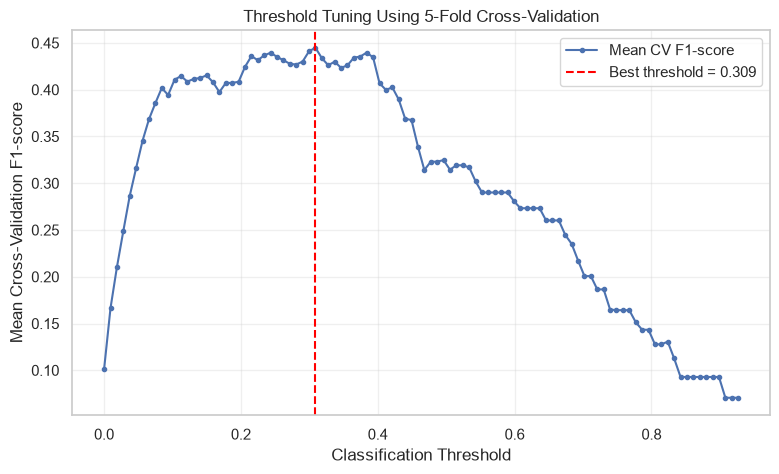

In [37]:

cv_results = pd.DataFrame(
    tuned_model.cv_results_
)

display(cv_results.head())

plt.figure(figsize=(9, 5))

plt.plot(
    cv_results["thresholds"],
    cv_results["scores"],
    marker=".",
    label="Mean CV F1-score"
)

plt.axvline(
    tuned_model.best_threshold_,
    color="red",
    linestyle="--",
    label=f"Best threshold = {tuned_model.best_threshold_:.3f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Mean Cross-Validation F1-score")
plt.title("Threshold Tuning Using 5-Fold Cross-Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [38]:

# Baseline model with default threshold
default_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

default_model.fit(X_train, y_train)

# Predictions on untouched test data
y_pred_default = default_model.predict(X_test)
y_pred_tuned = tuned_model.predict(X_test)

print("DEFAULT THRESHOLD (0.5)")
print(classification_report(y_test, y_pred_default, zero_division=0))

print("\nCROSS-VALIDATION TUNED THRESHOLD")
print(classification_report(y_test, y_pred_tuned, zero_division=0))


DEFAULT THRESHOLD (0.5)
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       473
           1       0.29      0.07      0.12        27

    accuracy                           0.94       500
   macro avg       0.62      0.53      0.54       500
weighted avg       0.91      0.94      0.92       500


CROSS-VALIDATION TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       473
           1       0.26      0.19      0.22        27

    accuracy                           0.93       500
   macro avg       0.61      0.58      0.59       500
weighted avg       0.92      0.93      0.92       500



In [39]:

comparison = pd.DataFrame({
    "Model": ["Default", "CV Tuned"],
    "Threshold": [0.5, tuned_model.best_threshold_],
    "Precision": [
        precision_score(y_test, y_pred_default, zero_division=0),
        precision_score(y_test, y_pred_tuned, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_default, zero_division=0),
        recall_score(y_test, y_pred_tuned, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_default, zero_division=0),
        f1_score(y_test, y_pred_tuned, zero_division=0)
    ]
})

display(comparison.round(3))


,Model,Threshold,Precision,Recall,F1-score
0,Default,0.500,0.286,0.074,0.118
1,CV Tuned,0.309,0.263,0.185,0.217
